In [1]:
import pandas as pd
import numpy as np

## 1. Business case & Data Collection

Este Notebook recoge un proyecto de ciencia de datos aplicado a la optimización del control de calidad en la producción y laminado en caliente de placas gruesas de acero. Su meta estratégica es reemplazar la inspección visual manual por un modelo proactivo basado en visión artificial y la metodología Six Sigma (Defecto Cero).

1. Contexto Industrial y Operativo

• Producto: Placas de acero estructural de alta resistencia (espesores ≥ 4.0 mm) bajo normativa UNE, destinadas a la construcción naval, puentes, torres eólicas y maquinaria pesada.
• Proceso de Fabricación: Se utiliza el método de Laminación en Caliente (Hot Rolling), que consta de tres etapas principales: Calentamiento (1.100 °C - 1.250 °C), Laminación (compresión mediante rodillos de gran presión) y Enfriamiento con Inspección automatizada.

2. Justificación Económica (Regla de Calidad 10X)

El proyecto demuestra su viabilidad financiera al evitar que los defectos avancen en el flujo industrial, donde los costes de subsanación se multiplican por 10 en cada fase:  
* Etapa 1 (Fábrica - Óptimo): Coste base de 70 € por tonelada (se recicla el material bruto).  
* Etapa 2 (Acabado): Sube a 700 € por tonelada (pérdida de energía, mano de obra y horas de maquinaria; se convierte en scrap).  
* Etapa 3 (Cliente Final): Escala a 7.000 € por tonelada (penalizaciones, logística inversa y daño reputacional).  
* Impacto: La detección temprana en la Fase 1 genera un ahorro potencial de 6.930 € por tonelada frente a un escape de calidad al cliente.  

3. Origen y Estructura de los Datos

* Dataset: "Steel Plates Faults", recolectado por el Semeion Research Center (Roma), financiado por el Centro Sviluppo Materiali y alojado en el repositorio UCI desde 2010.
* Captura: Realizada de forma automática mediante cámaras ópticas industriales de visión artificial instaladas en la línea de producción.
* Variables (34 en total):
	* 27 Independientes: Datos geométricos (coordenadas, perímetros), magnitud de la falla (área en píxeles), análisis óptico (brillo, luminosidad) e índices morfológicos de la silueta del defecto.
	* 7 Dependientes (Clases de Defectos): Clasificadas en Pastry (Pliegue), Z_Scratch (Raya), K_Scratch (Surco), Stains (Mancha), Dirtiness (Suciedad), Bumps (Abolladura) y Other_Faults (Otro).

## 2. Data Understanding

### 2.1 Exploratorio Inicial

In [2]:
#Cargo el dataframe desde un archivo CSV
df = pd.read_csv("./data/steel-faults.csv", sep=",")

In [3]:
#Obtengo el numero de filas y columnas de la tabla (utilizo una sola tabla)
print("Número de filas y columnas:", df.shape)

Número de filas y columnas: (1941, 34)


In [4]:
#Saco la información del dataframe (tipo de datos, cantidad de valores no nulos, etc.)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null   float64
 15  Empty_Index    

In [5]:
#Muestro los primeros registros del dataframe
df.head()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [6]:
#Muestro los últimos registros del dataframe
df.tail()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
1936,249,277,325780,325796,273,54,22,35033,119,141,...,-0.4286,0.0026,0.7254,0,0,0,0,0,0,1
1937,144,175,340581,340598,287,44,24,34599,112,133,...,-0.4516,-0.0582,0.8173,0,0,0,0,0,0,1
1938,145,174,386779,386794,292,40,22,37572,120,140,...,-0.4828,0.0052,0.7079,0,0,0,0,0,0,1
1939,137,170,422497,422528,419,97,47,52715,117,140,...,-0.0606,-0.0171,0.9919,0,0,0,0,0,0,1
1940,1261,1281,87951,87967,103,26,22,11682,101,133,...,-0.2000,-0.1139,0.5296,0,0,0,0,0,0,1


In [7]:
#Cambio a español el nombre de las columnas que luego mostraré en los gráficos
df = df.rename(columns={
    'TypeOfSteel_A300': 'A300', 
    'TypeOfSteel_A400': 'A400', 
    'Steel_Plate_Thickness': 'Espesor',
    'Pastry': 'Pliegue',
    'Z_Scratch': 'Raya', 
    'K_Scatch': 'Surco',
    'Stains': 'Mancha',
    'Dirtiness': 'Suciedad',
    'Bumps': 'Abolladura', 
    'Other_Faults': 'Otro',
    'Pixels_Areas': 'Area_Pixel', 
    'X_Perimeter': 'Perimetro_X', 
    'Sum_of_Luminosity': 'Sum_Luminosidad', 
    'Luminosity_Index': 'Indice_Luminosidad', 
    'Square_Index': 'Indice_Forma_Cuadrada'
})

### 2.2 Tabla de Variables

In [8]:
#Defino las listas de vbles en fn de su naturaleza
coordenadas = ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum']
magnitud = ['Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index']
intensidad = ['Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Luminosity_Index']
maq_mat = ['Length_of_Conveyer', 'A300', 'A400', 'Espesor']
forma = ['Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'Orientation_Index', 'SigmoidOfAreas']
defecto = ['Pliegue', 'Raya', 'Surco', 'Mancha', 'Suciedad', 'Abolladura', 'Otro']

In [9]:
#importo las funciones del archivo funciones.py
import sys
import os
sys.path.append(os.path.abspath('../'))
from utils.funciones import asignar_naturaleza, asignar_definicion

In [10]:
#Construyo el inventario
tabla_vbles = pd.DataFrame({
    'Variable': df.columns,
    'Tipo de Dato': df.dtypes.values,
    'Naturaleza': [asignar_naturaleza(c, coordenadas, magnitud, intensidad, maq_mat, forma, defecto) for c in df.columns],
    'Descripción': [asignar_definicion(c, coordenadas, magnitud, intensidad, maq_mat, forma, defecto) for c in df.columns]
})

tabla_vbles.sort_values(by='Naturaleza').reset_index(drop=True)

,Variable,Tipo de Dato,Naturaleza,Descripción
0,Length_of_Conveyer,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
1,A300,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
2,A400,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
3,Espesor,int64,Características de la Maquinaria y Material,Parámetros de configuración de la maquinaria y...
4,X_Minimum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
5,X_Maximum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
6,Y_Minimum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
7,Y_Maximum,int64,Coordenadas y Ubicación Espacial (Geometría de...,"Estas variables delimitan el ""cuadro contenedo..."
8,Minimum_of_Luminosity,int64,Intensidad y Luminosidad (Análisis Óptico),Indican cómo refleja la luz el defecto. Las fa...
9,Maximum_of_Luminosity,int64,Intensidad y Luminosidad (Análisis Óptico),Indican cómo refleja la luz el defecto. Las fa...


## 3. Data Cleaning

In [11]:
#Como ya vi en la info() del df que no hay nulos, compruebo ahora si tengo duplicados por si acaso
#importo la funcion
from utils.funciones import duplicados
duplicados(df)

El número total de elementos duplicados es de: 0


In [12]:
#Compruebo si tengo outliers
from utils.funciones import detectar_outliers
columnas_a_analizar = coordenadas + magnitud + intensidad + maq_mat + forma
tabla_outliers = detectar_outliers(df, columnas_a_analizar)
print(tabla_outliers)

                 Variable     Mínimo     Q1 (25%)  Mediana (50%)  \
0               X_Minimum     0.0000      51.0000   4.350000e+02   
1               X_Maximum     4.0000     192.0000   4.670000e+02   
2               Y_Minimum  6712.0000  471253.0000   1.204128e+06   
3               Y_Maximum  6724.0000  471281.0000   1.204136e+06   
4             Y_Perimeter     1.0000      13.0000   2.500000e+01   
5              LogOfAreas     0.3010       1.9243   2.240600e+00   
6             Log_X_Index     0.3010       1.0000   1.176100e+00   
7             Log_Y_Index     0.0000       1.0792   1.322200e+00   
8   Minimum_of_Luminosity     0.0000      63.0000   9.000000e+01   
9   Maximum_of_Luminosity    37.0000     124.0000   1.270000e+02   
10     Length_of_Conveyer  1227.0000    1358.0000   1.364000e+03   
11                   A300     0.0000       0.0000   0.000000e+00   
12                   A400     0.0000       0.0000   1.000000e+00   
13                Espesor    40.0000      40.000

In [13]:
#Creo una columna categórica para el tipo de acero
from utils.funciones import asignar_tipo_acero
df['Tipo_Acero'] = df.apply(asignar_tipo_acero, axis=1)
print(df['Tipo_Acero'].value_counts())
df[['A300', 'A400', 'Tipo_Acero']].head()

Tipo_Acero
A400    1164
A300     777
Name: count, dtype: int64


,A300,A400,Tipo_Acero
0,1,0,A300
1,1,0,A300
2,1,0,A300
3,0,1,A400
4,0,1,A400


In [14]:
#creo una columna categorica para el tipo de defecto
from utils.funciones import asignar_tipo_defecto
df['Tipo_Defecto'] = df.apply(lambda fila: asignar_tipo_defecto(fila, defecto), axis=1)
print(df['Tipo_Defecto'].value_counts())
df[defecto + ['Tipo_Defecto']].head()

Tipo_Defecto
Otro          673
Abolladura    402
Surco         391
Raya          190
Pliegue       158
Mancha         72
Suciedad       55
Name: count, dtype: int64


,Pliegue,Raya,Surco,Mancha,Suciedad,Abolladura,Otro,Tipo_Defecto
0,1,0,0,0,0,0,0,Pliegue
1,1,0,0,0,0,0,0,Pliegue
2,1,0,0,0,0,0,0,Pliegue
3,1,0,0,0,0,0,0,Pliegue
4,1,0,0,0,0,0,0,Pliegue


In [15]:
#Creo una tabla Tipo de Acero vs Tipo de Defecto
tabla_1 = pd.crosstab(df['Tipo_Acero'], df['Tipo_Defecto'], margins=True)

#Ordeno los nombres de las columnas basándonos en la fila 'All' (excluyendo el propio 'All')
columnas_ordenadas = tabla_1.loc['All'].drop('All').sort_values(ascending=False).index

#Reorganizo la tabla manteniendo 'All' al final
tabla_1[list(columnas_ordenadas) + ['All']]
tabla_1

Tipo_Defecto,Abolladura,Mancha,Otro,Pliegue,Raya,Suciedad,Surco,All
Tipo_Acero,,,,,,,,
A300,279,1,266,49,172,9,1,777
A400,123,71,407,109,18,46,390,1164
All,402,72,673,158,190,55,391,1941


De acuerdo a la tabla anterior:  
* El acero A300 parece vulnerable a las deformaciones físicas por impacto (Abolladura) y a las rayaaduras superficiales finas (Rayas).  
* Las rayas severas longitudinales (Surco) están ligadas de forma casi exclusiva al acero A400.
* Las manchas (Mancha) y la suciedad (Suciedad) penalizan más al A400, ya que, concentra 71 de las 72 manchas químicas (Mancha) y 46 de las 55 impurezas (Suciedad).

In [16]:
#Creo una tabla Espesor vs Tipo de Defecto
from utils.funciones import agrupar_espesores
df['Rango_Espesor'] = df['Espesor'].apply(agrupar_espesores)
tabla_2 = pd.crosstab(df['Rango_Espesor'], df['Tipo_Defecto'], margins=True)

#ORDENO FILAS: Separo la fila 'All', ordeno el resto por la columna 'All' y volvemos a unir
filas_ordenadas = tabla_2.iloc[:-1].sort_values(by='All', ascending=False)
tabla_final = pd.concat([filas_ordenadas, tabla_2.iloc[[-1]]])

#ORDENO COLUMNAS: Busco el orden de las columnas usando la fila 'All' (sin incluir el propio 'All')
columnas_por_cantidad = tabla_final.loc['All'].drop('All').sort_values(ascending=False).index

#Reorganizo las columnas de la tabla final dejando 'All' al extremo derecho
tabla_final[list(columnas_por_cantidad) + ['All']]


Tipo_Defecto,Otro,Abolladura,Surco,Raya,Pliegue,Mancha,Suciedad,All
Rango_Espesor,,,,,,,,
Fino (<= 60mm),226,152,390,8,52,71,13,912
Medio (61mm - 150mm),305,222,1,172,90,1,42,833
Grueso / Industrial (> 150mm),142,28,0,10,16,0,0,196
All,673,402,391,190,158,72,55,1941


De acuerdo a la tabla anterior parece que:   
* En los espesores más finos es más probable tener rayas superficiales.  
* Para espesores medios es más fácil que se produzcan abolladuras.  
* Y en espesores gruesos parece que la visión artificial no es capaz de identificar la mayoría de los defectos, asignándolos a 'Otro'.

## 4. Analysis

### 4.1 Análisis univariante

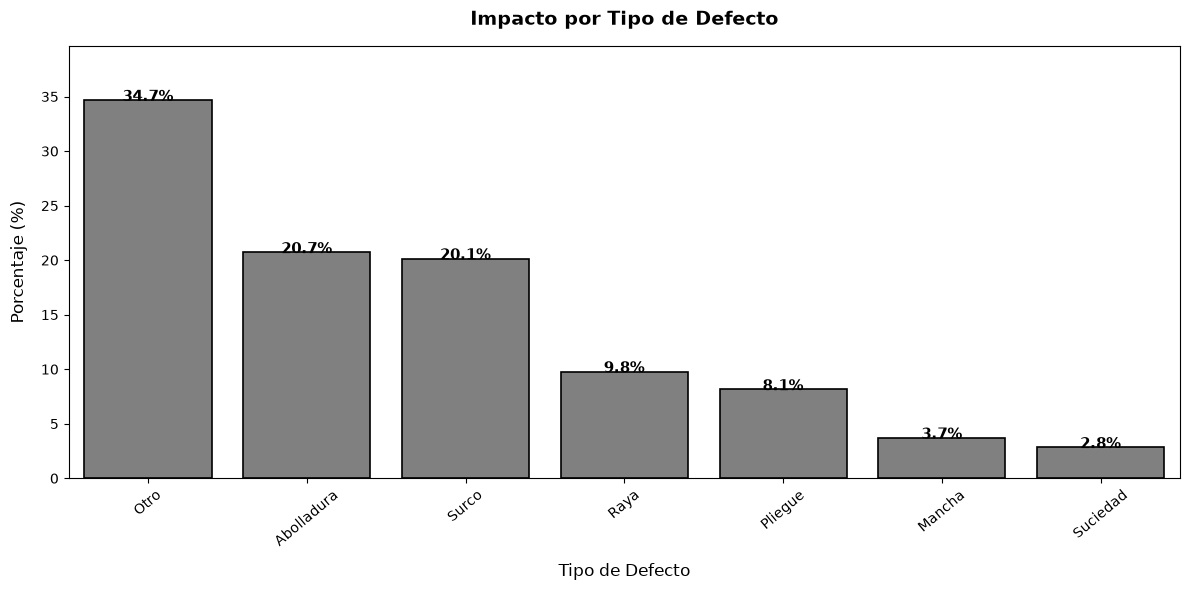

In [17]:
# Importamos las nuevas funciones desde tu carpeta utils
from utils.funciones import plot_porcentaje_defectos
plot_porcentaje_defectos(df)

#### CONCLUSIONES  
* El defecto más frecuente con diferencia es 'Otro' con un 34.7%. Más de una de cada tres defectos detectados en planta cae en esta categoría genérica. El sistema automático de visión artificial de la fábrica no es capaz de clasificar con precisión estas imperfecciones. Dejar un volumen tan alto (casi el 35%) sin identificar genera una ceguera operativa enorme. Aquí hay una OPORTUNIDAD millonaria para optimizar y reentrenar los algoritmos de clasificación de la planta.  
* Si limpiamos el dataset y dejamos fuera los errores no clasificados por el software, descubrimos el verdadero foco del problema: solo tres tipos de defectos (Abolladura, Surco y Raya) representan casi el 80% de todas las pérdidas por calidad de la planta (77.5%). Concentrar los esfuerzos de mantenimiento y calibración en estas tres áreas específicas erradicará de forma inmediata el grueso de las mermas en la producción de acero.  
* Las manchas químicas (3.7%) y la suciedad en el acero (2.8%) son los defectos menos frecuentes, sumando apenas un 6.5% entre ambos. Este es un punto muy positivo para la gestión de la planta. Te demuestra que los sistemas de descalillado hidráulico (limpieza con agua a alta presión) y los controles de pureza química en los slabs iniciales están funcionando de forma excelente. La suciedad no es el problema de esta fábrica.

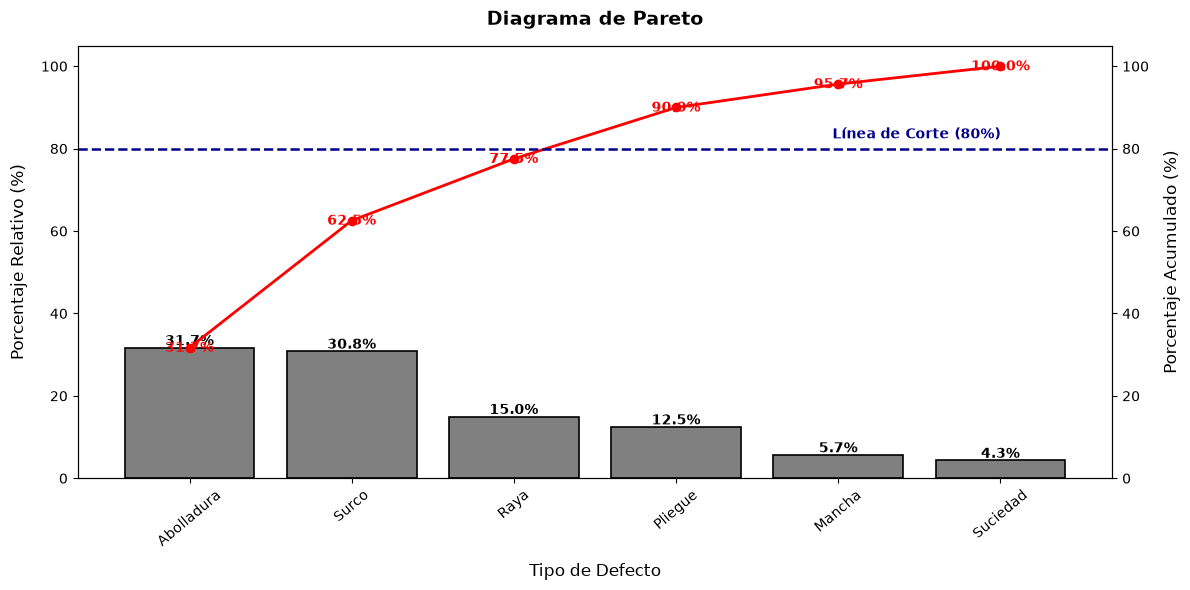

In [18]:
from utils.funciones import pareto_defectos
#Análisis de Pareto sin 'Other_Faults'
pareto_defectos(df)

Si limpiamos el dataset y dejamos fuera los errores no clasificados por el software, descubrimos el verdadero foco del problema: solo tres tipos de defectos (Abolladura, Surco y Raya) representan casi el 80% de todas las pérdidas por calidad de la planta (77.5%). Concentrar los esfuerzos de mantenimiento y calibración en estas tres áreas específicas erradicará de forma inmediata el grueso de las mermas en la producción de acero.

### 4.2 Análisis bivariante

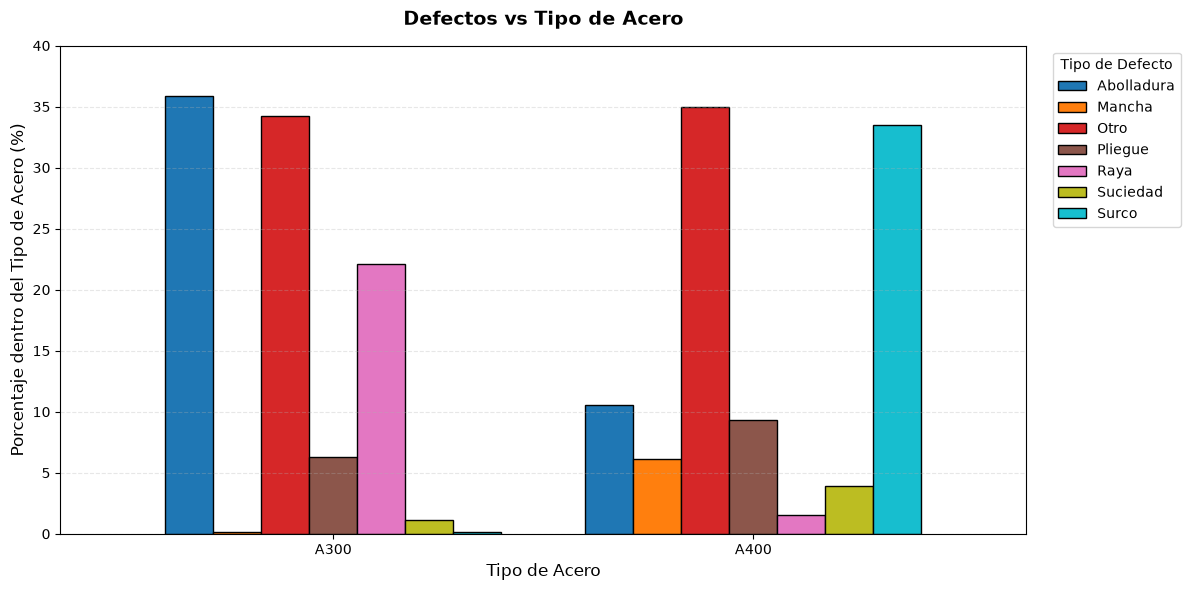

In [19]:
from utils.funciones import acero_vs_defecto
# Opción A: Barras separadas (Ideal para ver qué defecto sobresale en cada acero)
acero_vs_defecto(df, tipo_grafico='agrupado')

* En el gráfico anterior vimos que las Abolladuras y los Surcos acumulaban el grueso de los problemas identificados. Al cruzarlos con el tipo de acero, el dato nos da un diagnóstico claro: las Abolladuras son un problema exclusivo del acero blando A300, mientras que los surcos son una patología del acero duro A400.  
* El acero A300 es una aleación físicamente más blanda o maleable. Por lo tanto, cuando pasa por la línea, cualquier variación de presión en los rodillos lo deforma fácilmente provocando abolladuras. Las rayas que sufre son mayoritariamente superficiales y finas (Rayas), causadas por roces ligeros. Prácticamente no tiene rayas severas (Surcos).  
* En el acero A400, el panorama cambia radicalmente. El defecto identificado que más sobresale son las rayas severas (Surco ~34%). Además, es el único acero que presenta un porcentaje visible de manchas.  
* El porcentaje de fallos no clasificados (Otro) se mantiene alto y casi idéntico en ambos aceros (~34% en A300 y ~35% en A400). Esto confirma que el problema de identificación del software de visión artificial es un defecto sistemático de calibración global. No depende del tipo de acero que se esté fabricando; las cámaras fallan por igual a la hora de etiquetar de manera unívoca un tercio de la producción en ambas aleaciones.

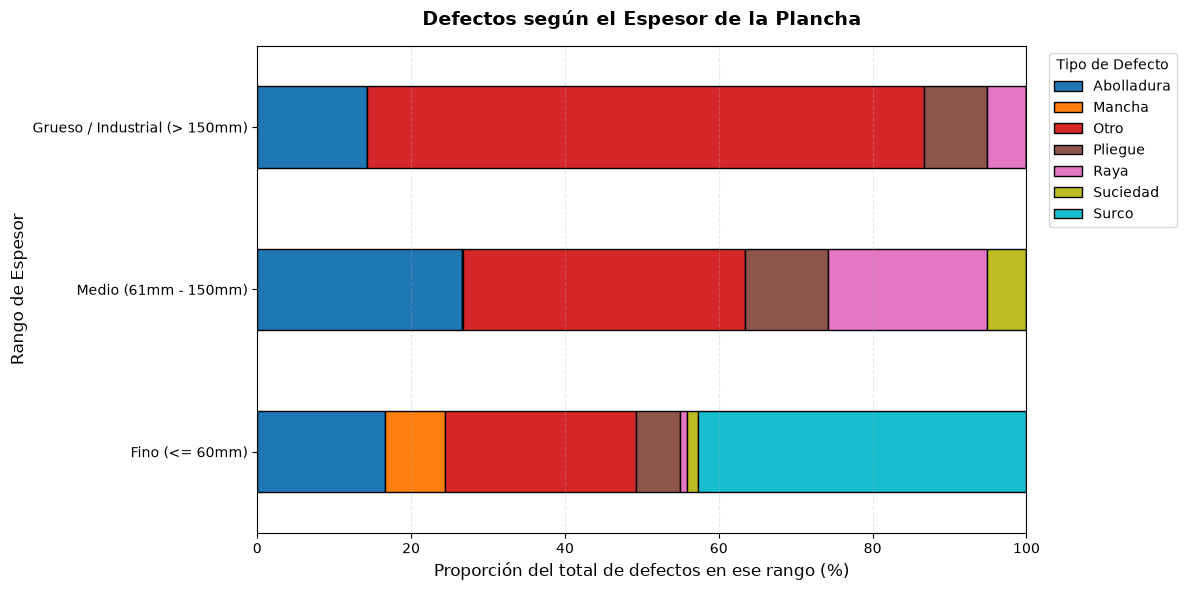

In [20]:
from utils.funciones import espesor_vs_defecto
espesor_vs_defecto(df)

* En las planchas finas, el defecto que predomina en la gráfica es Surco (ocupa más del 40% del total de fallas de este rango). Además, aquí se concentran de manera casi exclusiva las manchas.  
* En el espesor medio, desaparecen por completo las rayas severas (Surco), pero se disparan las abolladuras (con ~27%) y las rayas finas o superficiales (con ~20%).  
* En los bloques gruesos industriales, el gráfico lo ocupa casi todo Otro, que representa más del 70% de todas las mermas de esta categoría. El resto son pequeños porcentajes de Abolladura y Pliegue.  

### 4.3 Análisis multivariante

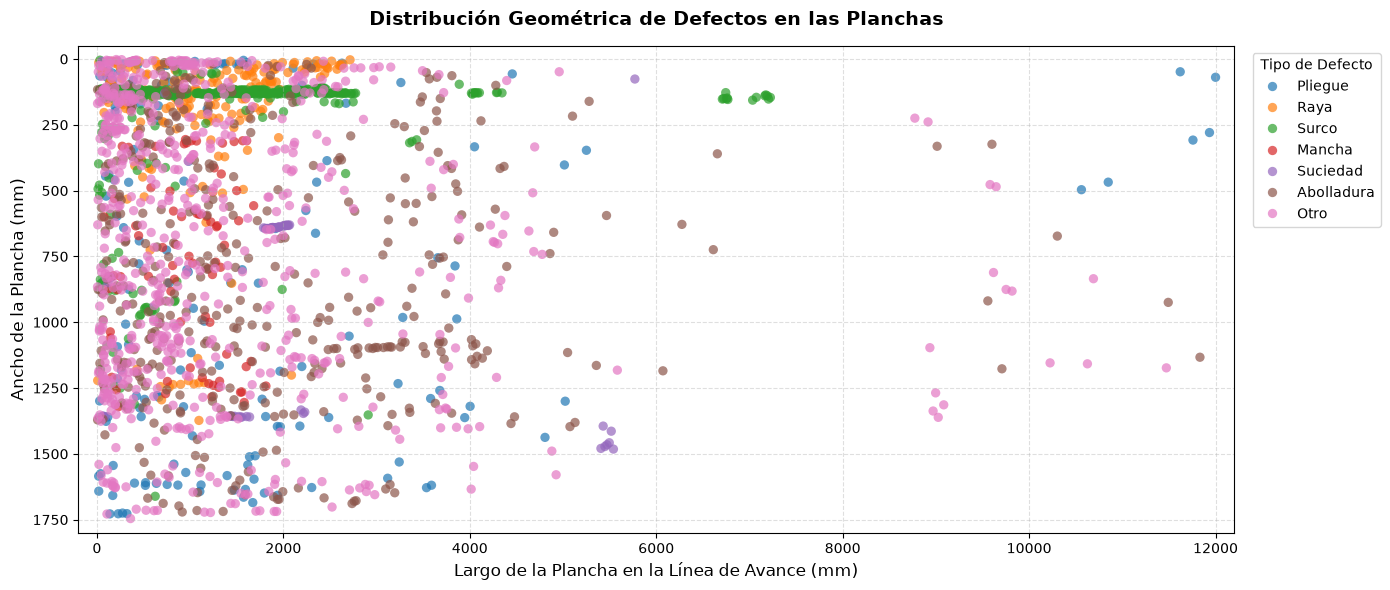

In [21]:
from utils.funciones import plot_plano_real_plancha

#Genero la simulación geométrica exacta de la línea de producción
plot_plano_real_plancha(df)


* La línea verde horizontal perfecta que cruza de izquierda a derecha. Está situada exactamente a un ancho de Ancho ≈ 120 mm (cerca del borde superior de la plancha) y se extiende de forma continua a lo largo del proceso. Parece un fallo mecánico sistemático y fijo en la maquinaria.  
* Hay una densa y masiva acumulación de puntos de todos los colores en el extremo izquierdo del mapa, concentrada drásticamente entre los 0 y los 3.000 mm (primeros 3 metros) de largo de las planchas. Pasada esa frontera, la superficie se limpia de forma notable. Delata una severa inestabilidad en el impacto inicial o "cabeza" de la plancha. Cuando el desbaste (slab) de acero incandescente golpea por primera vez los rodillos de deformación, sufre los peores choques térmicos, pérdidas de tracción y desajustes de presión. Una vez que la máquina transforma los primeros 3 metros y el proceso se estabiliza, el acero empieza a salir limpio.  
* El defecto Pliegue (solapamiento de metal) se concentra principalmente en la cabeza (primeros 2 metros) y se dispersa de forma aleatoria por el cuerpo de la plancha, compartiendo exactamente la misma distribución que las Abolladuras. Esto demuestra que es un fallo de origen metalúrgico heredado del desbaste (slab), donde las impurezas o burbujas internas del lingote original se abren y forman dobles capas debido a la enorme presión del proceso de laminación.
* Las rayas finas (Raya) y las manchas químicas (Mancha) se agrupan casi al 100% pegadas a la banda de Ancho = 0. Esto indica problemas de rozamiento con los topes de centrado automático cuando la plancha entra ligeramente desviada por el lateral superior de la mesa de rodillos, acumulando también ahí los líquidos refrigerantes que causan las reacciones químicas en el acero duro.

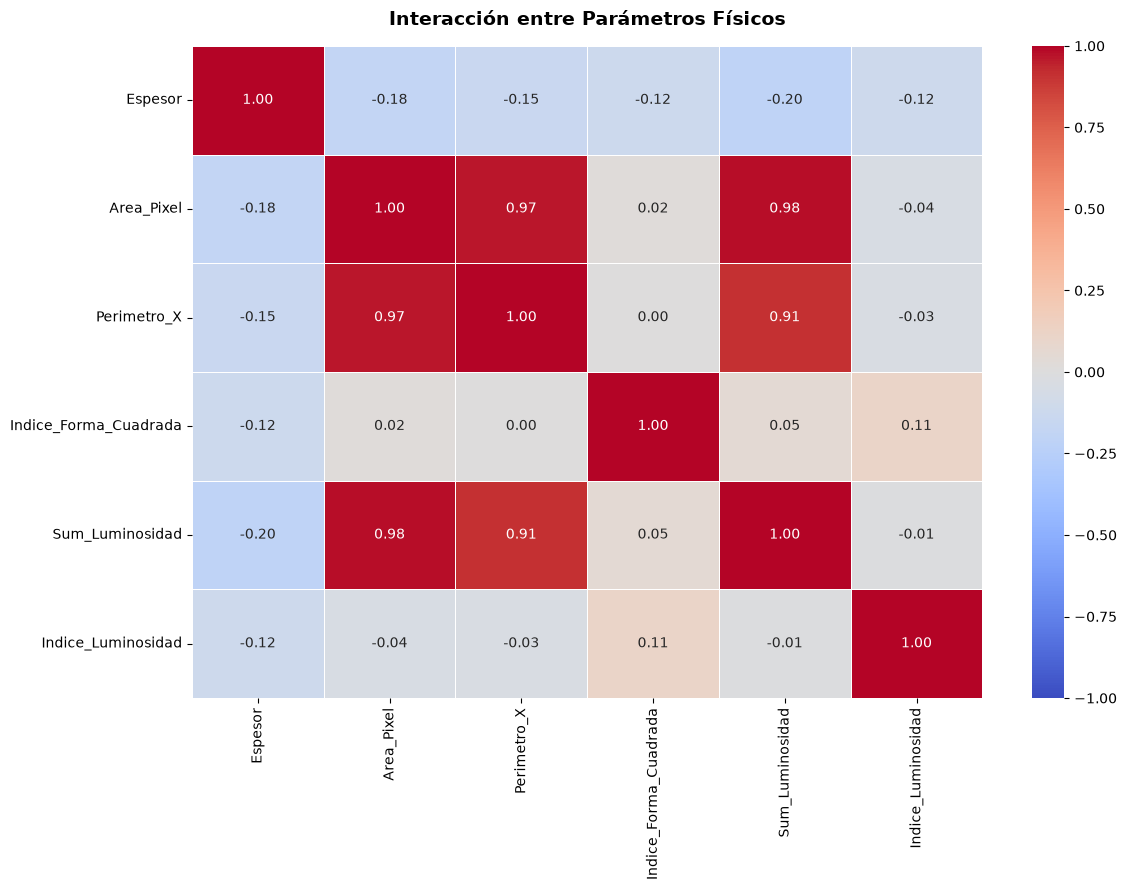

In [22]:
from utils.funciones import plot_multivariante_heatmap

#Heatmap (Evaluamos magnitudes físicas e intensidades ópticas juntas)
columnas_interes = ['Espesor', 'Area_Pixel', 'Perimetro_X', 'Indice_Forma_Cuadrada', 'Sum_Luminosidad', 'Indice_Luminosidad']
plot_multivariante_heatmap(df, columnas_interes)

* Existe una correlación casi perfecta (entre 0.91 y 0.98) entre el tamaño del defecto (Area_Pixel), su perímetro (Perimetro_X) y la luz total reflejada (Sum_Luminosida). Esto demuestra que el software calcula datos redundantes, lo que permite eliminar variables para aligerar la carga computacional de las cámaras sin perder precisión.  
* El grosor de la plancha (Espesor) tiene una correlación muy baja y negativa (entre -0.12 y -0.20) con el tamaño y brillo de las fallas. Esto confirma que el espesor influye en qué tipo de defecto aparece (visto en el bivariante), pero no condiciona la gravedad ni la magnitud física de la lesión una vez que se produce.  
* El índice de forma del fallo (Indice_Forma_Cuadrada) muestra una correlación prácticamente nula (~0.00) con el resto de las variables. Esto prueba que la silueta o morfología de la imperfección es independiente de su tamaño o luminosidad; es decir, la forma geométrica viene determinada exclusivamente por el tipo de accidente mecánico que la causó (un roce genera una línea, un impacto genera un cuadrado) y no por la gravedad o magnitud del defecto.

## 5. Resultados

En base a lo visto en el apartado enterior, paso a analizar las siguientes hipótesis:

### 5.1 Contraste de Hipótesis

#### 5.1.1 Hipótesis 1: Capacidad de Clasificar Defectos de la VA según el Espesor de las planchas

En el gráfico de distribución de defectos según el rango de espesor (fino, medio o gruesos), se observa que a medida que aumenta el espesor, aumenta la propoción de defectos clasificados como 'Otro'. Para abordar el problema, definimos dos hipótesis opuestas:

-   **Hipótesis Nula ($H_0$)**: El software de visión artificial tiene la misma capacidad para clasificar defectos independientemente del espesor de la plancha.
-   **Hipótesis Alternativa ($H_1$)**: La alta concentración de fallos en la categoría "Otro" (~35%) se debe a un sesgo sistemático en el algoritmo de clasificación, el cual pierde precisión (ceguera operativa) en ciertos rangos de espesor (como los bloques gruesos industriales, donde vimos que "Otro" superaba el 70%).

*Nota: Validaremos esta hipótesis mediante una prueba de Chi-cuadrado de Pearson sobre la tabla de contingencia en el siguiente bloque de código.*

In [30]:
import scipy.stats as stats
import pandas as pd

print("==================================================================")
print("CONTRASTE DE HIPÓTESIS TÉCNICA: SESGO DEL SOFTWARE SEGÚN ESPESOR")
print("==================================================================\n")

#Creo la tabla de contingencia de espesor vs defecto
tabla_espesor_defecto = pd.read_csv("./data/steel-faults.csv", sep=",") # (O como cargues tu df)
#Uso la columna de 'Rango_Espesor' y 'Tipo_Defecto'
tabla_contingencia = pd.crosstab(df['Rango_Espesor'], df['Tipo_Defecto'])

#Ejecuto el test de Chi-cuadrado
chi2, p_val, dof, expected = stats.chi2_contingency(tabla_contingencia)

print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"P-valor obtenido: {p_val:.4e}")

if p_val < 0.05:
    print("\nRESULTADO: Rechazamos la Hipótesis Nula (H0).")
    print("CONCLUSIÓN: Se demuestra matemáticamente que la tasa de fallos del software")
    print("depende del espesor. Pierde precisión drásticamente en bloques gruesos (>72%).")
else:
    print("\nRESULTADO: No se puede rechazar H0.")


CONTRASTE DE HIPÓTESIS TÉCNICA: SESGO DEL SOFTWARE SEGÚN ESPESOR

Estadístico Chi-cuadrado: 865.5110
P-valor obtenido: 1.4579e-177

RESULTADO: Rechazamos la Hipótesis Nula (H0).
CONCLUSIÓN: Se demuestra matemáticamente que la tasa de fallos del software
depende del espesor. Pierde precisión drásticamente en bloques gruesos (>72%).


**Plan de Acción Derivado del Contraste de Hipótesis**

*   **Auditar datos:** Revisar y balancear el dataset original, verificando si faltan imágenes de acero grueso en el entrenamiento de la IA.
*   **Calibrar óptica:** Ajustar el enfoque automático y la iluminación dinámica para planchas gruesas (debido al cambio de distancia a la lente y la retención de radiación térmica).
*   **Dividir modelos:** Sustituir el clasificador global por tres submodelos de IA independientes y especializados por rango de grosor (Fino, Medio y Grueso).
*   **Control humano temporal:** Activar un protocolo de revisión manual provisional enfocado *únicamente* en la salida del acero grueso mientras se reentrena el algoritmo.


#### 5.1.2 Hipótesis 2: Influencia del Material en el Tipo de Defectos generados

Al cruzar los datos de las patologías reales con la aleación del metal, observamos que las Abolladuras se concentran casi al 100% en el acero A300, mientras que los Surcos y las Manchas son característicos del acero A400. Planteamos el siguiente contraste estadístico:

*   **Hipótesis Nula ($H_0$)**: La aparición y tipología de los defectos mecánicos es independiente del tipo de material (aleación A300 vs A400) que se esté fabricando. (Asumiendo que las propiedades físicas del metal no influyen en cómo se daña).
*   **Hipótesis Alternativa ($H_1$)**: El tipo de defecto generado depende significativamente del tipo de material. (Sosteniendo que la maleabilidad del acero blando A300 lo hace vulnerable a deformaciones por impacto como las Abolladuras, mientras que la rigidez del acero duro A400 provoca fricciones severas que generan Surcos).

*Nota: Validaremos esta hipótesis mediante una prueba de Chi-cuadrado de Pearson sobre la tabla de contingencia en el siguiente bloque de código.*

In [32]:
import scipy.stats as stats
import pandas as pd

print("==================================================================")
print("CONTRASTE DE HIPÓTESIS 2: INFLUENCIA DE LA ALEACIÓN EN LOS DEFECTOS REALES")
print("==================================================================\n")

#Filtro el DataFrame para excluir la categoría genérica "Otro"
#Esto permite evaluar estrictamente la relación entre el material y los defectos reales
df_defectos_reales = df[df['Tipo_Defecto'] != 'Otro']

#Genero un tabla cruzando el Acero con los Defectos Reales
tabla_acero_defectos_reales = pd.crosstab(df_defectos_reales['Tipo_Acero'], df_defectos_reales['Tipo_Defecto'])

#Ejecuto el test de Chi-cuadrado de Pearson
chi2_mat, p_val_mat, dof_mat, expected_mat = stats.chi2_contingency(tabla_acero_defectos_reales)

print(f"Estadístico Chi-cuadrado: {chi2_mat:.4f}")
print(f"Grados de libertad: {dof_mat}")
print(f"P-valor obtenido: {p_val_mat:.4e}")

#Nivel de significación (alfa) estándar = 5%
alpha = 0.05

if p_val_mat < alpha:
    print("\nRESULTADO: Rechazamos la Hipótesis Nula (H0).")
    print("CONCLUSIÓN: Se confirma estadísticamente la Hipótesis Alternativa (H1).")
    print("La aparición y tipología de los defectos DEPENDE directamente del tipo de material")
    print("y sus propiedades físicas inherentes (A300 vs A400).")
else:
    print("\nRESULTADO: No se puede rechazar la Hipótesis Nula (H0).")
    print("CONCLUSIÓN: No existe suficiente evidencia para afirmar que el material influya en los fallos.")


CONTRASTE DE HIPÓTESIS 2: INFLUENCIA DE LA ALEACIÓN EN LOS DEFECTOS REALES

Estadístico Chi-cuadrado: 665.4197
Grados de libertad: 5
P-valor obtenido: 1.4702e-141

RESULTADO: Rechazamos la Hipótesis Nula (H0).
CONCLUSIÓN: Se confirma estadísticamente la Hipótesis Alternativa (H1).
La aparición y tipología de los defectos DEPENDE directamente del tipo de material
y sus propiedades físicas inherentes (A300 vs A400).


**Plan de Acción Derivado del Contraste de Hipótesis**

*   **Calibración inteligente:** Automatizar los parámetros de presión de la línea según la aleación que entra en producción.
*   **Mitigación en Acero A300 (Blando):** Amortiguar picos de presión para evitar deformaciones físicas (Abolladuras).
*   **Mantenimiento para Acero A400 (Duro):** Instalar rodamientos rotativos para reducir la fricción abrasiva (Surcos) y limpieza mecánica de los rodillos.
*   **Limpieza química en A400:** Optimizar el soplado de agua a alta presión para eliminar residuos superficiales (Manchas).


#### 5.1.3 Hipótesis 3: Inestabilidad en la Fase Inicial de Laminación (Análisis Espacial de Largo)

El mapa geométrico de la plancha reveló una masiva acumulación de defectos en los primeros 3.000 mm (3 metros) de largo, estabilizándose el proceso a partir de esa frontera. Planteamos el siguiente contraste:

*   **Hipótesis Nula ($H_0$)**: Los defectos se distribuyen de forma uniforme y aleatoria a lo largo de todo el eje X (Largo) de la plancha. (Asumiendo que el avance del proceso es estable desde el inicio).
*   **Hipótesis Alternativa ($H_1$)**: Los defectos se concentran significativamente en la "cabeza" de la plancha (0-3000 mm). (Sostieniendo que existe una severa inestabilidad transitoria durante la fase de entrada del bloque incandescente a los rodillos, provocada por pérdidas de tracción o choques térmicos).

*Nota: Para demostrar esta hipótesis espacial, utilizaremos el Test de Kolmogorov-Smirnov.*

In [34]:
import scipy.stats as stats
import numpy as np

print("==================================================================")
print("CONTRASTE DE HIPÓTESIS 3: INESTABILIDAD EN LA FASE INICIAL DE LA LAMINACIÓN")
print("==================================================================\n")

#Normalizo el largo de los datos reales para el test (rango 0 a 1)
largo_norm = (df['Y_Minimum'] + df['Y_Maximum']) / 2
largo_norm = (largo_norm - largo_norm.min()) / (largo_norm.max() - largo_norm.min())

#Comparo lo datos reales con una distribución uniforme teórica
ks_stat_x, p_val_x = stats.kstest(largo_norm, 'uniform')
print(f"P-valor obtenido en Largo: {p_val_x:.4e}")
if p_val_x < 0.05:
    print("Resultado: RECHAZAMOS H0. Los defectos NO son aleatorios; se concentran al inicio (cabeza).")

CONTRASTE DE HIPÓTESIS 3: INESTABILIDAD EN LA FASE INICIAL DE LA LAMINACIÓN

P-valor obtenido en Largo: 0.0000e+00
Resultado: RECHAZAMOS H0. Los defectos NO son aleatorios; se concentran al inicio (cabeza).


**Plan de Acción Derivado del Contraste de Hipótesis:**
*   **Ajuste de entrada:** Optimizar la amortiguación hidráulica y las pinzas de arrastre al inicio del tren de laminación.
*   **Control térmico:** Precalentar homogéneamente la cabeza del desbaste (slab) para mitigar el impacto por choque térmico.

#### 5.1.4 Hipótesis 4: Fallo Mecánico Sistemático en Maquinaria (Análisis Espacial de Ancho)

El mapa geométrico detectó una línea perfecta y continua de defectos a lo largo de todo el eje Y (Ancho) fija en la coordenada de ~120 mm. Planteamos el siguiente contraste:

*   **Hipótesis Nula ($H_0$)**: Los defectos se distribuyen de forma uniforme y aleatoria a lo largo del eje Y (Ancho) de la plancha. (Asumiendo que no hay elementos mecánicos dañando zonas específicas).
*   **Hipótesis Alternativa ($H_1$)**: Existe una concentración anómala y lineal de defectos en una coordenada fija de ancho (~120 mm). (Sostieniendo la presencia de un fallo mecánico crítico y repetitivo, como una muesca, cuerpo extraño o desgaste fijo en un rodillo específico).

*Nota: Para demostrar esta hipótesis espacial, utilizaremos el Test de Kolmogorov-Smirnov.*

In [36]:
print("==================================================================")
print("CONTRASTE DE HIPÓTESIS 4: FALLO SITEMÁTICO EN EL TREN DE LAMINACIÓN")
print("==================================================================\n")

# Normalizamos el ancho (coordenada Y de la plancha)
ancho_norm = (df['X_Minimum'] + df['X_Maximum']) / 2
ancho_norm = (ancho_norm - ancho_norm.min()) / (ancho_norm.max() - ancho_norm.min())

ks_stat_y, p_val_y = stats.kstest(ancho_norm, 'uniform')
print(f"P-valor obtenido en Ancho: {p_val_y:.4e}")
if p_val_y < 0.05:
    print("Resultado: RECHAZAMOS H0. Hay un patrón lineal repetitivo (fallo mecánico fijo).")

CONTRASTE DE HIPÓTESIS 4: FALLO SITEMÁTICO EN EL TREN DE LAMINACIÓN

P-valor obtenido en Ancho: 2.4421e-119
Resultado: RECHAZAMOS H0. Hay un patrón lineal repetitivo (fallo mecánico fijo).


**Plan de Acción Derivado del Contraste de Hipótesis:**
*   **Inspección línea:** Detener la línea para revisar físicamente el rodillo exactamente a 120 mm de su borde.
*   **Corrección mecánica:** Reparar o sustituir el componente dañado para eliminar la causa raíz del rayado continuo.

### 5.2 Plan de Acción  
A continuación se recoge el Plan de Acción (AP) completo derivado de este Analisis Exploratiorio de Datos (EDA)

#### Bloque 1: Acciones Correctivas Mecánicas
*   **Intervención urgente a 120 mm (Eje Y):** Programar una parada de mantenimiento técnica para inspeccionar el rodillo laminador exactamente a 120 mm de su borde superior. Se debe identificar y rectificar la presencia de muescas, virutas incrustadas o desgastes localizados que están provocando el rayado continuo (**Surcos**) documentado.
*   **Estabilización de la Cabeza de la Plancha (Eje X):** Implementar un protocolo de ajuste en las pinzas de arrastre y optimizar la amortiguación hidráulica del tren de laminación en caliente durante los primeros 3.000 mm (3 metros) de avance. 
*   **Homogeneización Térmica:** Precalentar los desbastes (slabs) de forma más homogénea en el horno de recocido para reducir el choque térmico y la pérdida de tracción inicial que disparan los defectos por impacto en la entrada de la línea.

#### Bloque 2: Calibración Dinámica de Línea
*   **Protocolo de Laminación para Acero A300 (Blando):** Programar una reducción automática en los picos de presión ejercidos por los rodillos cuando el sistema detecte el procesamiento de esta aleación blanda. El objetivo es suavizar los puntos de contacto físico para erradicar el 100% de las **Abolladuras** y **Pliegues**.
*   **Protocolo de Guiado para Acero A400 (Duro):** Sustituir las guías laterales de fricción fija por rodamientos rotativos libres de abrasión para que este acero de alta resistencia no sufra rozamientos severos (**Surcos**).
*   **Optimización del Descalillado:** Incrementar la presión del soplado de agua en el sistema de descalillado hidráulico para arrastrar por completo los residuos químicos y de cascarilla que penalizan selectivamente al acero duro en forma de **Manchas**.

#### Bloque 3: Auditoría Técnica del Sistema
*   **Recalibración Óptica:** Ajustar la distancia focal y la ganancia de exposición de las cámaras de visión artificial. Al incrementarse el espesor de las planchas, disminuye la distancia física al lente y aumenta la radiación infrarroja, lo que ciega al algoritmo actual.
*   **Contingencia Operativa Temporal:** Disponer un retén provisional de inspectores de calidad visual humana a la salida del tren de laminación, enfocado **únicamente** en el rango de bloques gruesos (>150 mm) para subsanar la ceguera del software (72.4% de fallos etiquetados como "Otro") sin ralentizar el flujo de las planchas finas y medias.


### 5.3 Productivización

Habiendo demostrado con total certeza matemática y respaldo estadístico que el software actual de las cámaras sufre un fallo crítico condicionado por el grosor del acero, la implementación una Fase II del proyecto consistiría en desplegar un **sistema inteligente por etapas**:

1.  **Filtro e identificación inicial:** En cuanto la plancha entra en la línea, el sistema detecta automáticamente su grosor y este dato actúa como un desviador inteligente, enviando la información al "experto digital" que corresponda.
2.  **Especialización a medida (Tres Inteligencias Artificiales):** Sustituiremos el programa único actual por tres modelos de Inteligencia Artificial especializados. Para garantizar respuestas instantáneas en la propia línea de producción (evitando retrasos en la toma de decisiones), el sistema procesará la información directamente en los equipos de la planta:
    *   **Modelo Planchas Finas $\le$ 60 mm):** Optimizado para detectar grietas profundas (*Surcos*) y (*Manchas*).
    *   **Modelo Espesores Medios 61-150 mm):** Experto en identificar deformaciones por impacto (*Abolladuras*) y (*Rayas*).
    *   **Modelo Bloques Gruesos $>$ 150 mm):** Entrenado exclusivamente con imágenes de bloques industriales pesados. Esto resolverá de forma definitiva el 72.4% de "ceguera" que el software actual etiqueta erróneamente como "Otro".
3.  **Mantenimiento y actualización automatizada:** El sistema se vigilará a sí mismo de forma continua para detectar cambios en las condiciones de la fábrica (desgaste de rodillos, cambios de luz, etc.). Si el volumen de fallos sin clasificar sube del 5%, el sistema enviará una alerta e iniciará una actualización automática.


### 5.4 Presentación de Resultados

El presente proyecto de Data Science aplicado a la industria siderúrgica realizado durante el Bootcamp de DS con IA (The_Bridge, Bilbao 2026), concluye con los siguientes hallazgos:

1.  **Foco en el Problema Real (Principio de Pareto):** Si bien el dataset registra una amplia variedad de patologías, el análisis demuestra que controlando y erradicando únicamente tres defectos (**Abolladuras, Surcos y Rayas**), la fábrica eliminaría de golpe el **77.5% de sus mermas de producción**, maximizando el retorno de inversión en mantenimiento.
2.  **Ceguera Tecnológica Mitigada:** Se ha descubierto y probado científicamente que el sistema de visión artificial actual no es ineficiente por igual en todas las producciones, sino que posee un fallo de diseño especialmente para espesores gruesos. Corregir este algoritmo bajo una arquitectura segmentada por espesores salvaría al proceso del 'punto ciego' del software y recuperaría la visibilidad total sobre la calidad de los bloques industriales (Gruesos).
3.  **Excelencia Operativa Detectada:** El estudio arroja una conclusión muy positiva: los defectos de *Suciedad* y *Manchas* son marginales (6.5% conjunto). Esto convalida el excelente rendimiento de los equipos de filtrado y los sistemas de descalillado hidráulico de la planta, permitiendo desviar los recursos de inversión de esas áreas hacia las correcciones mecánicas críticas del tren de rodillos.
4.  **Impacto Financiero:** La implementación del Plan de Acción propuesto derivado del estudio Analítico de Datos, transformaría el departamento de calidad de un centro de costes reactivo a un motor proactivo de eficiencia, con una capacidad de ahorro directo de **6.930 € por cada tonelada de acero** que se impida avanzar con defectos hacia el cliente final.

#### ******Ver archivo 'Presentación.pptx'*****
